In [1]:
import sys
print(sys.executable)

D:\Fraudulent-Job-Detection\.venv\Scripts\python.exe


In [2]:
# ============================================
# FRAUDULENT JOB POSTING DETECTION
# 01 - DATASET UNDERSTANDING
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

sns.set_theme(style="whitegrid")

# Dataset path
DATA_PATH = Path(
    r"D:\Fraudulent-Job-Detection\data\raw\fake_job_postings.csv\fake_job_postings.csv"
)

# Load original dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("=" * 60)
print("Shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Shape: (17880, 18)
Number of rows: 17880
Number of columns: 18


In [3]:
# First five records
display(df.head())

# Last five records
display(df.tail())

# Column names
print("\nCOLUMN NAMES:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

# Data types and non-null counts
print("\nDATASET INFORMATION:")
df.info()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them ever...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- ...","Experience with content management systems a major plus (any blogging counts!)Familiar with the Food52 editorial voice and aestheticLoves food, ap...",NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Production Service enabling brands and agencies to get ...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing skills? Maybe Account Management? ...And think ad...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Seconds team and freelance community throughout the vid...",What you will get from usThrough being part of the 90 Seconds team you will gain:experience working on projects located around the world with an i...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,"Valor Services provides Workforce Solutions that meet the needs of companies across the Private Sector, with a special focus on the Oil &amp; Gas ...","Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assistant that possesses strong supervisory skills and ...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activities with subcontractor’s assigned crew that perta...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life through geography is at the heart of everything we do. Esri’s geographic information system (GIS) techn...,THE COMPANY: ESRI – Environmental Systems Research InstituteOur passion for improving quality of life through geography is at the heart of everyth...,"EDUCATION: Bachelor’s or Master’s in GIS, business administration, or a related field, or equivalent work experience, depending on position levelE...","Our culture is anything but corporate—we have a collaborative, creative environment; phone directories organized by first name; a relaxed dress co...",0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,"SpotSource Solutions LLC is a Global Human Capital Management Consulting firm headquartered in Miami, Florida. Founded in January 2012, SpotSource...","JOB TITLE: Itemization Review ManagerLOCATION: Fort Worth, TX DEPARTMENT: Itemization Re...","QUALIFICATIONS:RN license in the State of TexasDiploma or Bachelors of Science in Nursing, requiredPast managerial experience, preferred6 + years’...",Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
17875,17876,Account Director - Distribution,"CA, ON, Toronto",Sales,NaN,"Vend is looking for some awesome new talent to come join us. You'll be working in an awesome team doing awesome things, and generally being awesom...",Just in case this is the first time you’ve visited our website Vend is an award winning web based point of sale software for retail. We’re chuckin...,To ace this role you:Will eat comprehensive Statements of Work for breakfastHave been working in Enterprise Sales or Account Management preferably...,What can you expect from us?We have an open culture where we openly share our results and where your input is truly valued.We'll have a great envi...,0,1,1,Full-time,Mid-Senior level,NaN,Computer Software,Sales,0
17876,17877,Payroll Accountant,"US, PA, Philadelphia",Accounting,NaN,"WebLinc is the e-commerce platform and services provider for the fastest growing online retailers. WebLinc’s modern, agile technologies and strate...","The Payroll Accountant will focus primarily on payroll functions for approximately 100 (and counting!) employees. In addition, this individual wil...",- B.A. or B.S. in Accounting- Desire to have fun while doing what you love!- Genuine passion for Accounting and Payroll and the drive to take owne...,Health &amp; WellnessMedical planPrescription drug planDental planVision planFlexible spending accountShort-term disabilityLong-term disabilityGym...,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Internet,Accounting/Auditing,0
17877,17878,Project Cost Control Staff Engineer - Cost Control Exp - TX,"US, TX, Houston",NaN,NaN,We Provide Full Time Permanent Positions for many medium to large US companies. We are interested in finding/recruiting high quality candidates in...,Experienced Project Cost Control Staff Engineer is required having responsibility to provide proper variance explanation and root causes analysis ...,At least 12 years professional experience.Ability to work in a diverse team environmentA minimum of 8 years of experience in project cost control ...,NaN,0,0,0,Full-time,NaN,NaN,NaN,NaN,0
17878,17879,Graphic Designer,"NG, LA, Lagos",NaN,NaN,NaN,Nemsia Studios is looking for an experienced visual/graphic designer to join our Lagos office. The idealcandidate will be versatile in both print ...,"1. Must be fluent in the latest versions of Corel &amp; Adobe CC (Esp. Photoshop, Illustrator &amp; Indesign) 2. Have a strong interest in interac...","Competitive salary (compensation will be based on experience) Casual attire At Nemsia Studios you are assured of a pleasant, enthusiastic, fast pa...",0,0,1,Contract,Not Applicable,Professional,Graphic Design,Design,0
17879,17880,Web Application Developers,"NZ, N, Wellington",Engineering,NaN,"Vend is looking for some awesome new talent to come join us. You'll be working in an awesome team doing awesome things, and generally being awesom...",Who are we?Vend is an award winning web based point of sale software for retail. We’re chucking out crusty old cash registers and replacing them ...,We want to hear from you if:You have an in-depth understanding of OO programmingYou totally get MVC and multi-tier architectureYou have experience...,NaN,0,1,1,Full-time,Mid-Senior level,NaN,Computer Software,Engineering,0



COLUMN NAMES:
1. job_id
2. title
3. location
4. department
5. salary_range
6. company_profile
7. description
8. requirements
9. benefits
10. telecommuting
11. has_company_logo
12. has_questions
13. employment_type
14. required_experience
15. required_education
16. industry
17. function
18. fraudulent

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 

In [4]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing)

,Missing Count,Missing Percentage
salary_range,15012,83.959732
department,11547,64.580537
required_education,8105,45.329978
benefits,7212,40.335570
required_experience,7050,39.429530
function,6455,36.101790
industry,4903,27.421700
employment_type,3471,19.412752
company_profile,3308,18.501119
requirements,2696,15.078300


TARGET VARIABLE ANALYSIS

Unique target values:
[0 1]

Class counts:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Class percentages:
fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64


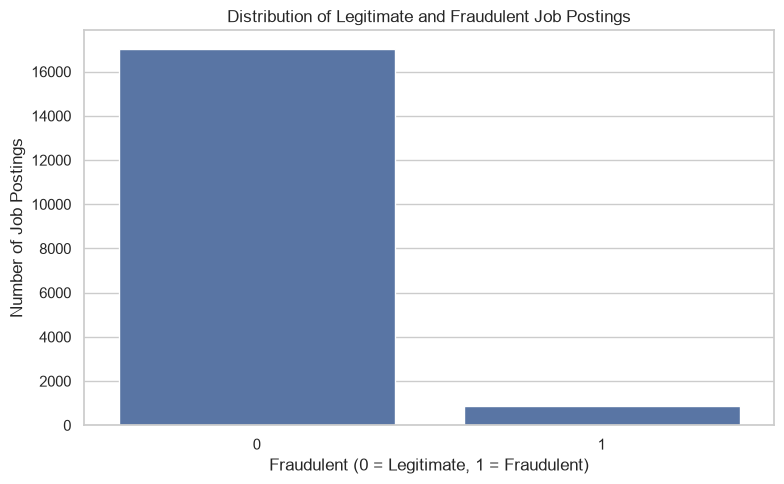

In [5]:
print("TARGET VARIABLE ANALYSIS")

print("\nUnique target values:")
print(df["fraudulent"].unique())

print("\nClass counts:")
print(df["fraudulent"].value_counts())

print("\nClass percentages:")
print(
    df["fraudulent"]
    .value_counts(normalize=True)
    .mul(100)
)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="fraudulent"
)

ax.set_title("Distribution of Legitimate and Fraudulent Job Postings")
ax.set_xlabel("Fraudulent (0 = Legitimate, 1 = Fraudulent)")
ax.set_ylabel("Number of Job Postings")

plt.tight_layout()
plt.show()

In [6]:
print("DUPLICATE ANALYSIS")

print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate rows excluding the first occurrence:",
    df.duplicated(keep="first").sum()
)

print(
    "Unique records:",
    len(df.drop_duplicates())
)

DUPLICATE ANALYSIS
Exact duplicate rows: 0
Duplicate rows excluding the first occurrence: 0
Unique records: 17880


In [7]:
print("IDENTIFIER ANALYSIS")

print("Total records:", len(df))
print("Unique job IDs:", df["job_id"].nunique())
print("Missing job IDs:", df["job_id"].isnull().sum())

print(
    "Repeated job IDs:",
    df["job_id"].duplicated().sum()
)

IDENTIFIER ANALYSIS
Total records: 17880
Unique job IDs: 17880
Missing job IDs: 0
Repeated job IDs: 0


In [8]:
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

df_audit = df.copy()

# Normalize text for duplicate investigation only
for col in text_columns:
    df_audit[col] = (
        df_audit[col]
        .fillna("")
        .astype(str)
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

df_audit["combined_text"] = (
    df_audit[text_columns]
    .agg(" ".join, axis=1)
    .str.strip()
)

# Identify repeated textual records
duplicate_mask = df_audit.duplicated(
    subset=["combined_text"],
    keep=False
)

duplicate_records = df_audit[duplicate_mask]

print("Total records:", len(df_audit))
print("Records belonging to repeated-text groups:",
      len(duplicate_records))

print("Number of repeated-text groups:",
      duplicate_records["combined_text"].nunique())

# Check whether duplicate text has conflicting labels
conflicts = (
    duplicate_records
    .groupby("combined_text")["fraudulent"]
    .nunique()
)

print("Groups with conflicting fraud labels:",
      (conflicts > 1).sum())

Total records: 17880
Records belonging to repeated-text groups: 2755
Number of repeated-text groups: 747
Groups with conflicting fraud labels: 0


In [9]:
print("TEXT QUALITY ANALYSIS")

for col in text_columns:

    text = df[col].fillna("").astype(str)

    empty_count = text.str.strip().eq("").sum()

    print(f"\nColumn: {col}")
    print("Missing:", df[col].isnull().sum())
    print("Empty strings:", empty_count)
    print("Average length:", text.str.len().mean())
    print("Median length:", text.str.len().median())
    print("Maximum length:", text.str.len().max())

TEXT QUALITY ANALYSIS

Column: title
Missing: 0
Empty strings: 0
Average length: 28.530313199105144
Median length: 25.0
Maximum length: 142

Column: company_profile
Missing: 3308
Empty strings: 3308
Average length: 620.9014541387024
Median length: 570.0
Maximum length: 6178

Column: description
Missing: 1
Empty strings: 2
Average length: 1218.004418344519
Median length: 1017.0
Maximum length: 14907

Column: requirements
Missing: 2696
Empty strings: 2698
Average length: 590.1322147651007
Median length: 467.0
Maximum length: 10864

Column: benefits
Missing: 7212
Empty strings: 7220
Average length: 208.89569351230426
Median length: 45.0
Maximum length: 4429


In [10]:
print("LEGITIMATE JOB POSTING")
display(
    df[df["fraudulent"] == 0][
        ["title", "company_profile", "description",
         "requirements", "fraudulent"]
    ].head(2)
)

print("\nFRAUDULENT JOB POSTING")
display(
    df[df["fraudulent"] == 1][
        ["title", "company_profile", "description",
         "requirements", "fraudulent"]
    ].head(2)
)

LEGITIMATE JOB POSTING


,title,company_profile,description,requirements,fraudulent
0,Marketing Intern,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them ever...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- ...","Experience with content management systems a major plus (any blogging counts!)Familiar with the Food52 editorial voice and aestheticLoves food, ap...",0
1,Customer Service - Cloud Video Production,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Production Service enabling brands and agencies to get ...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing skills? Maybe Account Management? ...And think ad...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Seconds team and freelance community throughout the vid...",0



FRAUDULENT JOB POSTING


,title,company_profile,description,requirements,fraudulent
98,IC&E Technician,Staffing &amp; Recruiting done right for the Oil &amp; Energy Ind...,"IC&amp;E Technician | Bakersfield, CA Mt. PosoPrincipal Duties and Responsibilities: Calibrates, tests, maintains, troubleshoots, and installs all...","QualificationsKnowledge, Skills &amp; Abilities: A high school diploma or GED is required. Must have a valid driver’s license. Ability to read, wr...",1
144,Forward Cap.,NaN,The group has raised a fund for the purchase of homes in the Southeast. The student on this project will help them build their investments from th...,NaN,1


In [11]:
# ============================================
# DUPLICATE GROUP ANALYSIS
# ============================================

group_summary = (
    df_audit
    .groupby("combined_text")
    .agg(
        number_of_records=("job_id", "count"),
        number_of_labels=("fraudulent", "nunique"),
        fraud_label=("fraudulent", "first")
    )
)

repeated_groups = group_summary[
    group_summary["number_of_records"] > 1
]

print("TOTAL UNIQUE TEXT GROUPS:", len(group_summary))
print("REPEATED TEXT GROUPS:", len(repeated_groups))

print(
    "Records belonging to repeated groups:",
    repeated_groups["number_of_records"].sum()
)

print(
    "Extra repeated records beyond first occurrence:",
    (repeated_groups["number_of_records"] - 1).sum()
)

print("\nGROUP SIZE DISTRIBUTION:")
display(
    repeated_groups["number_of_records"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of occurrences")
    .to_frame("Number of groups")
)

print("\nFRAUD LABEL DISTRIBUTION IN REPEATED GROUPS:")
display(repeated_groups["fraud_label"].value_counts())

TOTAL UNIQUE TEXT GROUPS: 15872
REPEATED TEXT GROUPS: 747
Records belonging to repeated groups: 2755
Extra repeated records beyond first occurrence: 2008

GROUP SIZE DISTRIBUTION:


,Number of groups
Number of occurrences,
2,466
3,137
4,64
5,28
6,13
7,13
8,3
9,2
10,2



FRAUD LABEL DISTRIBUTION IN REPEATED GROUPS:


fraud_label
0    707
1     40
Name: count, dtype: int64

In [12]:
# ============================================
# MISSINGNESS BY TARGET CLASS
# ============================================

text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

missing_by_class = []

for col in text_columns:

    for label in [0, 1]:

        subset = df[df["fraudulent"] == label]

        missing_count = subset[col].isnull().sum()

        blank_count = (
            subset[col]
            .notna()
            .astype(bool)
            .mul(
                subset[col]
                .fillna("")
                .astype(str)
                .str.strip()
                .eq("")
            )
            .sum()
        )

        missing_by_class.append({
            "Feature": col,
            "Class": "Fraudulent" if label == 1 else "Legitimate",
            "Total Postings": len(subset),
            "Missing": missing_count,
            "Blank": blank_count,
            "Missing %": missing_count / len(subset) * 100
        })

missing_class_df = pd.DataFrame(missing_by_class)

display(
    missing_class_df.round(2)
)

,Feature,Class,Total Postings,Missing,Blank,Missing %
0,title,Legitimate,17014,0,0,0.00
1,title,Fraudulent,866,0,0,0.00
2,company_profile,Legitimate,17014,2721,0,15.99
3,company_profile,Fraudulent,866,587,0,67.78
4,description,Legitimate,17014,0,0,0.00
5,description,Fraudulent,866,1,1,0.12
6,requirements,Legitimate,17014,2542,2,14.94
7,requirements,Fraudulent,866,154,0,17.78
8,benefits,Legitimate,17014,6848,8,40.25
9,benefits,Fraudulent,866,364,0,42.03


In [13]:
# ============================================
# TEXT LENGTH ANALYSIS BY CLASS
# ============================================

length_results = []

for col in text_columns:

    valid_text = df[col].dropna().astype(str)

    temp = pd.DataFrame({
        "fraudulent": df.loc[valid_text.index, "fraudulent"],
        "length": valid_text.str.len()
    })

    for label in [0, 1]:

        subset = temp[temp["fraudulent"] == label]

        length_results.append({
            "Feature": col,
            "Class": "Fraudulent" if label == 1 else "Legitimate",
            "Count": len(subset),
            "Mean Length": subset["length"].mean(),
            "Median Length": subset["length"].median()
        })

length_df = pd.DataFrame(length_results)

display(length_df.round(2))

,Feature,Class,Count,Mean Length,Median Length
0,title,Legitimate,17014,28.42,25.0
1,title,Fraudulent,866,30.67,28.0
2,company_profile,Legitimate,14293,762.73,684.0
3,company_profile,Fraudulent,279,716.67,718.0
4,description,Legitimate,17014,1221.22,1027.0
5,description,Fraudulent,865,1156.17,846.0
6,requirements,Legitimate,14472,702.41,569.0
7,requirements,Fraudulent,712,542.53,349.5
8,benefits,Legitimate,10166,349.33,237.0
9,benefits,Fraudulent,502,366.06,233.5


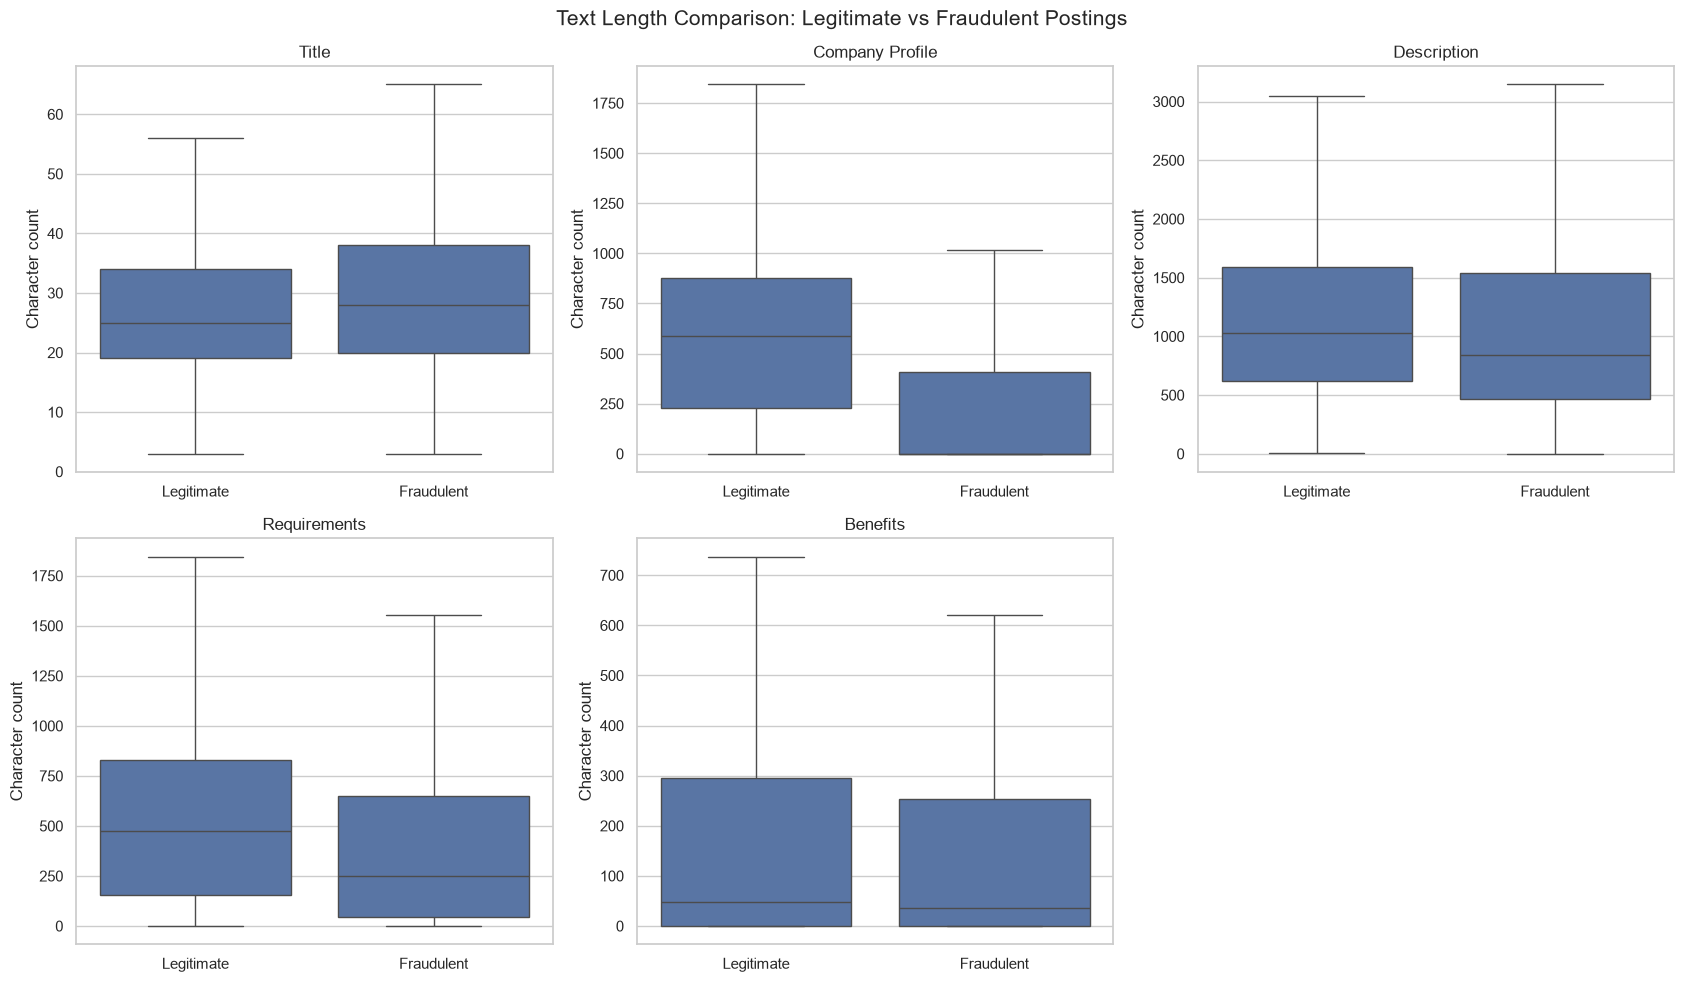

In [14]:
# ============================================
# TEXT LENGTH DISTRIBUTIONS
# ============================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

axes = axes.flatten()

for i, col in enumerate(text_columns):

    temp = pd.DataFrame({
        "Length": df[col].fillna("").astype(str).str.len(),
        "Class": df["fraudulent"].map({
            0: "Legitimate",
            1: "Fraudulent"
        })
    })

    sns.boxplot(
        data=temp,
        x="Class",
        y="Length",
        ax=axes[i],
        showfliers=False
    )

    axes[i].set_title(f"{col.replace('_', ' ').title()}")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Character count")

axes[-1].axis("off")

plt.suptitle(
    "Text Length Comparison: Legitimate vs Fraudulent Postings",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [15]:
# ============================================
# INVESTIGATE LARGEST DUPLICATE GROUPS
# ============================================

# Group using individual normalized text fields.
# This avoids ambiguity from joining fields into one string.

exact_groups = (
    df_audit
    .groupby(text_columns, dropna=False)
    .agg(
        records=("job_id", "size"),
        fraud_labels=("fraudulent", "nunique"),
        label=("fraudulent", "first")
    )
    .reset_index()
    .sort_values("records", ascending=False)
)

repeated_exact_groups = exact_groups[
    exact_groups["records"] > 1
]

print("Repeated groups:", len(repeated_exact_groups))

print("\nTOP 10 LARGEST DUPLICATE GROUPS:")

display(
    repeated_exact_groups[
        ["records", "fraud_labels", "label"] + text_columns
    ].head(10)
)

# Inspect the largest group
largest_group = repeated_exact_groups.iloc[0]

print("\nLARGEST GROUP SIZE:", largest_group["records"])
print("Fraud label:", largest_group["label"])

print("\nTEXT FIELD LENGTHS:")

for col in text_columns:
    value = largest_group[col]
    print(f"{col}: {len(str(value))} characters")

# Retrieve original dataset records matching this group
mask = pd.Series(True, index=df_audit.index)

for col in text_columns:
    mask &= df_audit[col].eq(largest_group[col])

largest_group_rows = df.loc[mask]

print("\nORIGINAL RECORDS IN LARGEST GROUP:")
print("Number of records:", len(largest_group_rows))

display(
    largest_group_rows[
        ["job_id"] + text_columns + ["fraudulent"]
    ].head(10)
)

Repeated groups: 747

TOP 10 LARGEST DUPLICATE GROUPS:


,records,fraud_labels,label,title,company_profile,description,requirements,benefits
4759,375,1,0,english teacher abroad,we help teachers get safe &amp; secure jobs abroad :),"play with kids, get paid for it love travel? jobs in asia$1,500+ usd monthly ($200 cost of living)housing provided (private/furnished)airfare reim...",university degree required. tefl / tesol / celta or teaching experience preferred but not necessarycanada/us passport holders only,see job description
6003,46,1,0,graduates: english teacher abroad (conversational),we help teachers get safe &amp; secure jobs abroad :),"play with kids, get paid for it love travel? jobs in asia$1500 usd + monthly ($200 cost of living)excellent for student loans/credit cardshousing ...",university degree required. tefl / tesol / celta or teaching experience preferred but not necessarypositive attitude required. canada/us passport ...,see job description
5997,40,1,0,graduates: english teacher abroad,we help teachers get safe &amp; secure jobs abroad :),"play with kids, get paid for it :-)love travel? jobs in asia$1500 usd + monthly ($200 cost of living)housing providedairfare reimbursedexcellent f...",university degree required. tefl / tesol / celta or teaching experience preferred but not necessarypositive attitude required. canada/us passport ...,see job description
5999,32,1,0,graduates: english teacher abroad (conversational),we help teachers get safe &amp; secure jobs abroad :),"play with kids, get paid for it :-)love travel? jobs in asia$1500 usd + monthly ($200 cost of living)housing providedairfare reimbursedexcellent f...",university degree required. tefl / tesol / celta or teaching experience preferred but not necessarypositive attitude required. canada/us passport ...,see job description
4760,26,1,0,english teacher abroad,we help teachers get safe &amp; secure jobs abroad :),"play with kids, get paid for it love travel? jobs in asia$1,500+ usd monthly ($200 cost of living)housing provided (private/furnished)airfare reim...",university degree required. tefl / tesol / celta or teaching experience preferred but not necessarycanada/us passport holders only,see job description
4848,25,1,0,entry level sales,,"general summary: achieves maximum sales profitability, growth and account penetration within an assigned territory and/or market segment by effect...",,great health and dentalfast advancement opportunitiesgreat income potentialcompetitive bonus programcar allowance
4766,24,1,0,english teacher abroad (conversational),we help teachers get safe &amp; secure jobs abroad :),"play with kids, get paid for it.vacancies in asia$1500 usd + monthly ($200 cost of living)housing providedairfare reimbursedexcellent for student ...","university degree required. tefl / tesol / celta, and/or teaching experience preferredcanada/us passport holders only",see job description
6001,24,1,0,graduates: english teacher abroad (conversational),we help teachers get safe &amp; secure jobs abroad :),"play with kids, get paid for it :-)love travel? openings in china$1500 usd + monthly ($200 cost of living)housing providedairfare reimbursedexcell...",university degree required. tefl / tesol / celta or teaching experience preferred but not necessarypositive attitude required. canada/us passport ...,see job description
2894,21,1,1,cruise staff wanted *urgent*,,6* ultra luxury american cruise company is urgently looking for the following positions:*hospitality - for the many bars &amp; restaurants on boar...,"certification &amp; experience: previous experience (not required)good english speaker, some customer service skills, wanting to learn &amp; work.","benefits: on board en suite accommodation and food, medical cover for duration of contract, world work visa, free wifi, tax free salary &amp; more!"
6437,21,1,1,home based payroll typist/data entry clerks positions available,,"we have several openings available in this area earning $1000.00-$2500.00 per week. we are seeking only honest, self-motivated 


LARGEST GROUP SIZE: 375
Fraud label: 0

TEXT FIELD LENGTHS:
title: 22 characters
company_profile: 53 characters
description: 380 characters
requirements: 130 characters
benefits: 19 characters

ORIGINAL RECORDS IN LARGEST GROUP:
Number of records: 375


,job_id,title,company_profile,description,requirements,benefits,fraudulent
35,36,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0
40,41,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0
48,49,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0
62,63,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0
80,81,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0
89,90,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0
99,100,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0
101,102,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0
119,120,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0
122,123,English Teacher Abroad,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare Reim...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,See job description,0


In [16]:
# ============================================
# COMPANY PROFILE MISSINGNESS BY CLASS
# ============================================

df_missing = df.copy()

df_missing["company_profile_missing"] = (
    df_missing["company_profile"].isna()
)

missing_analysis = pd.crosstab(
    df_missing["fraudulent"],
    df_missing["company_profile_missing"],
    normalize="index"
) * 100

missing_analysis.index = [
    "Legitimate",
    "Fraudulent"
]

missing_analysis.columns = [
    "Profile Available",
    "Profile Missing"
]

display(missing_analysis.round(2))

,Profile Available,Profile Missing
Legitimate,84.01,15.99
Fraudulent,32.22,67.78


In [17]:
# ============================================
# METADATA VARIATION IN LARGEST DUPLICATE GROUP
# ============================================

metadata_columns = [
    col for col in df.columns
    if col not in text_columns + ["job_id", "fraudulent"]
]

print("METADATA VARIATION IN LARGEST GROUP")

variation = pd.DataFrame({
    "Unique Values": largest_group_rows[
        metadata_columns
    ].nunique(dropna=False),

    "Missing Values": largest_group_rows[
        metadata_columns
    ].isnull().sum()
})

display(variation)

print("\nMETADATA VALUES THAT VARY:")

varying_columns = variation[
    variation["Unique Values"] > 1
].index.tolist()

for col in varying_columns:
    print(f"\n{col}")
    display(
        largest_group_rows[col]
        .value_counts(dropna=False)
    )

METADATA VARIATION IN LARGEST GROUP


,Unique Values,Missing Values
location,371,0
department,1,375
salary_range,1,375
telecommuting,1,0
has_company_logo,1,0
has_questions,1,0
employment_type,1,0
required_experience,1,375
required_education,1,0
industry,1,0



METADATA VALUES THAT VARY:

location


location
US, CA, Sacramento           2
US, WI, Milwaukee            2
US, MO, Jefferson City       2
US, MT, Missoula             2
US, NY, Saint Bonaventure    1
                            ..
US, TN, Nashville            1
US, VA, Richmond             1
US, CA, Palo Alto            1
US, CA, Hayward              1
US, TX, Houston              1
Name: count, Length: 371, dtype: int64

In [18]:
# ============================================
# STRUCTURED FEATURE ANALYSIS
# ============================================

print("NUMERICAL / BINARY FEATURES")

numeric_columns = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

display(df[numeric_columns].describe())

print("\nCATEGORICAL FEATURE CARDINALITY")

categorical_columns = [
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function",
    "department",
    "location"
]

for col in categorical_columns:
    print(
        f"{col}: {df[col].nunique(dropna=True)} "
        f"unique values | "
        f"{df[col].isna().sum()} missing"
    )

NUMERICAL / BINARY FEATURES


,telecommuting,has_company_logo,has_questions
count,17880.000000,17880.000000,17880.000000
mean,0.042897,0.795302,0.491723
std,0.202631,0.403492,0.499945
min,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000
50%,0.000000,1.000000,0.000000
75%,0.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000



CATEGORICAL FEATURE CARDINALITY
employment_type: 5 unique values | 3471 missing
required_experience: 7 unique values | 7050 missing
required_education: 13 unique values | 8105 missing
industry: 131 unique values | 4903 missing
function: 37 unique values | 6455 missing
department: 1337 unique values | 11547 missing
location: 3105 unique values | 346 missing


In [19]:
# ============================================
# BINARY FEATURES BY FRAUD CLASS
# ============================================

for col in numeric_columns:

    print(f"\nFEATURE: {col}")

    result = pd.crosstab(
        df["fraudulent"],
        df[col],
        normalize="index"
    ) * 100

    display(result.round(2))


FEATURE: telecommuting


telecommuting,0,1
fraudulent,,
0,95.87,4.13
1,92.61,7.39



FEATURE: has_company_logo


has_company_logo,0,1
fraudulent,,
0,18.09,81.91
1,67.32,32.68



FEATURE: has_questions


has_questions,0,1
fraudulent,,
0,49.79,50.21
1,71.13,28.87


In [20]:
# ============================================
# MISSINGNESS ACROSS ALL FEATURES BY CLASS
# ============================================

missing_results = []

for col in df.columns:

    for label in [0, 1]:

        subset = df[df["fraudulent"] == label]

        missing_results.append({
            "Feature": col,
            "Class": "Fraudulent" if label == 1 else "Legitimate",
            "Missing Count": subset[col].isna().sum(),
            "Missing Percentage": (
                subset[col].isna().mean() * 100
            )
        })

missing_all_df = pd.DataFrame(missing_results)

display(
    missing_all_df
    .pivot(
        index="Feature",
        columns="Class",
        values="Missing Percentage"
    )
    .round(2)
)

Class,Fraudulent,Legitimate
Feature,,
benefits,42.03,40.25
company_profile,67.78,15.99
department,61.32,64.75
description,0.12,0.00
employment_type,27.83,18.98
fraudulent,0.00,0.00
function,38.91,35.96
has_company_logo,0.00,0.00
has_questions,0.00,0.00


In [21]:
# ============================================
# CATEGORICAL FEATURE DISTRIBUTION BY CLASS
# ============================================

categorical_features = [
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

for col in categorical_features:

    print("\n" + "=" * 65)
    print("FEATURE:", col)

    temp = df[[col, "fraudulent"]].copy()

    temp[col] = temp[col].fillna("MISSING")

    distribution = pd.crosstab(
        temp[col],
        temp["fraudulent"],
        normalize="columns"
    ) * 100

    distribution.columns = [
        "Legitimate (%)",
        "Fraudulent (%)"
    ]

    distribution["Total"] = temp[col].value_counts()

    distribution = distribution.sort_values(
        "Total",
        ascending=False
    )

    display(distribution.head(15).round(2))


FEATURE: employment_type


,Legitimate (%),Fraudulent (%),Total
employment_type,,,
Full-time,65.42,56.58,11620
MISSING,18.98,27.83,3471
Contract,8.70,5.08,1524
Part-time,4.25,8.55,797
Temporary,1.40,0.23,241
Other,1.25,1.73,227



FEATURE: required_experience


,Legitimate (%),Fraudulent (%),Total
required_experience,,,
MISSING,38.88,50.23,7050
Mid-Senior level,21.72,13.05,3809
Entry level,14.80,20.67,2697
Associate,13.25,4.85,2297
Not Applicable,6.21,6.93,1116
Director,2.19,1.96,389
Internship,2.18,1.15,381
Executive,0.77,1.15,141



FEATURE: required_education


,Legitimate (%),Fraudulent (%),Total
required_education,,,
MISSING,44.99,52.08,8105
Bachelor's Degree,29.65,11.55,5145
High School or equivalent,11.23,19.63,2080
Unspecified,7.85,7.04,1397
Master's Degree,2.26,3.58,416
Associate Degree,1.58,0.69,274
Certification,0.89,2.19,170
Some College Coursework Completed,0.58,0.35,102
Professional,0.41,0.46,74



FEATURE: industry


,Legitimate (%),Fraudulent (%),Total
industry,,,
MISSING,27.20,31.76,4903
Information Technology and Services,10.00,3.70,1734
Computer Software,8.06,0.58,1376
Internet,6.24,0.00,1062
Marketing and Advertising,4.60,5.20,828
Education Management,4.83,0.00,822
Financial Services,4.37,4.04,779
Hospital & Health Care,2.62,5.89,497
Consumer Services,1.96,2.77,358



FEATURE: function


,Legitimate (%),Fraudulent (%),Total
function,,,
MISSING,35.96,38.91,6455
Information Technology,10.09,3.70,1749
Sales,8.39,4.73,1468
Engineering,7.26,13.05,1348
Customer Service,6.83,7.74,1229
Marketing,4.82,1.15,830
Administrative,3.00,13.74,630
Design,1.98,0.35,340
Health Care Provider,1.98,0.12,338


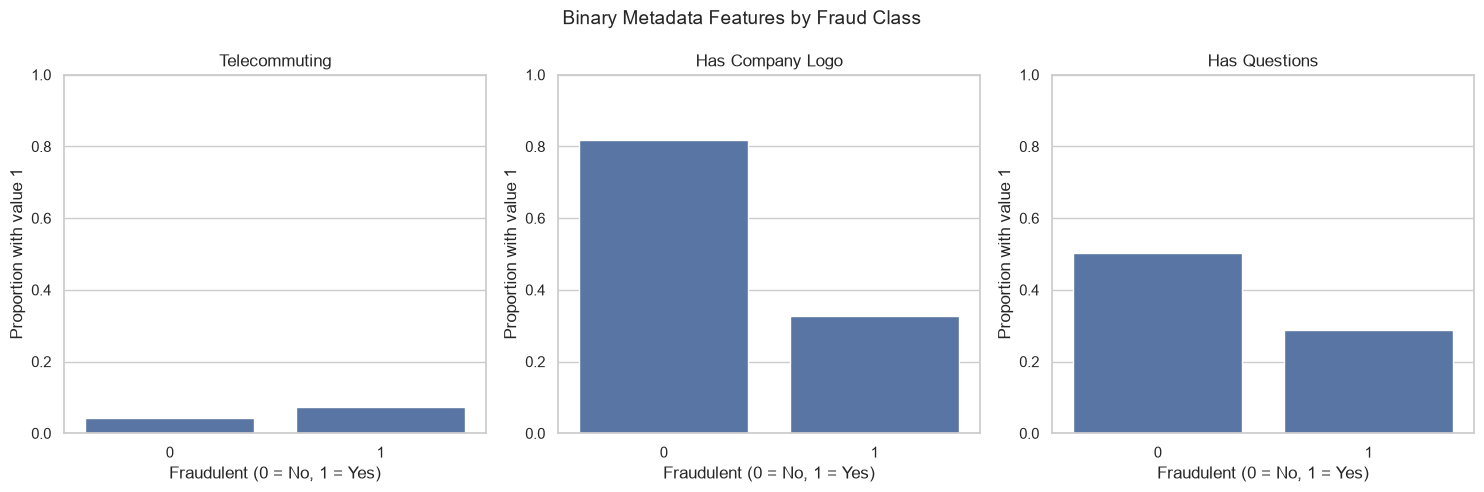

In [22]:
# ============================================
# BINARY FEATURE COMPARISON
# ============================================

binary_features = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

for i, col in enumerate(binary_features):

    sns.barplot(
        data=df,
        x="fraudulent",
        y=col,
        ax=axes[i],
        errorbar=None
    )

    axes[i].set_title(
        col.replace("_", " ").title()
    )

    axes[i].set_xlabel(
        "Fraudulent (0 = No, 1 = Yes)"
    )

    axes[i].set_ylabel(
        "Proportion with value 1"
    )

    axes[i].set_ylim(0, 1)

plt.suptitle(
    "Binary Metadata Features by Fraud Class",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [24]:
# ============================================
# GROUP IDENTIFICATION FOR LEAKAGE PREVENTION
# ============================================

from sklearn.model_selection import StratifiedGroupKFold

# Recreate normalized text fields for grouping
group_text = df[text_columns].copy()

for col in text_columns:
    group_text[col] = (
        group_text[col]
        .fillna("")
        .astype(str)
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

# Create a group ID from all five normalized text fields
groups = pd.util.hash_pandas_object(
    group_text,
    index=False
)

y = df["fraudulent"].astype(int)

print("Total records:", len(df))
print("Unique text groups:", groups.nunique())
print("Repeated text groups:", (groups.value_counts() > 1).sum())

# Verify that each identical-text group has one label
label_counts = (
    pd.DataFrame({
        "group": groups,
        "fraudulent": y
    })
    .groupby("group")["fraudulent"]
    .nunique()
)

conflicting_groups = (label_counts > 1).sum()

print("Groups with conflicting labels:", conflicting_groups)

assert conflicting_groups == 0, (
    "Conflicting labels found. Investigate before splitting."
)

Total records: 17880
Unique text groups: 15872
Repeated text groups: 747
Groups with conflicting labels: 0


In [25]:
# ============================================
# STRATIFIED GROUP-AWARE TRAIN/TEST SPLIT
# ============================================

RANDOM_STATE = 42

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# First fold is our predetermined held-out test fold
train_idx, test_idx = next(
    splitter.split(df, y, groups)
)

X_train = df.iloc[train_idx].copy()
X_test = df.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("TRAINING SET")
print("Rows:", len(X_train))
print("Fraudulent:", y_train.sum())
print("Legitimate:", (y_train == 0).sum())
print("Fraud percentage:", round(y_train.mean() * 100, 2))

print("\nTEST SET")
print("Rows:", len(X_test))
print("Fraudulent:", y_test.sum())
print("Legitimate:", (y_test == 0).sum())
print("Fraud percentage:", round(y_test.mean() * 100, 2))

print("\nTRAIN SIZE:", round(len(X_train) / len(df) * 100, 2), "%")
print("TEST SIZE:", round(len(X_test) / len(df) * 100, 2), "%")

# Verify no text group crosses the split
overlap = set(groups_train).intersection(set(groups_test))

print("\nGROUP OVERLAP:", len(overlap))

assert len(overlap) == 0

TRAINING SET
Rows: 14304
Fraudulent: 693
Legitimate: 13611
Fraud percentage: 4.84

TEST SET
Rows: 3576
Fraudulent: 173
Legitimate: 3403
Fraud percentage: 4.84

TRAIN SIZE: 80.0 %
TEST SIZE: 20.0 %

GROUP OVERLAP: 0


In [26]:
# ============================================
# CLASS DISTRIBUTION AFTER GROUP SPLITTING
# ============================================

split_distribution = pd.DataFrame({
    "Original": y.value_counts(normalize=True) * 100,
    "Training": y_train.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
})

split_distribution.index = [
    "Legitimate",
    "Fraudulent"
]

display(split_distribution.round(2))

,Original,Training,Testing
Legitimate,95.16,95.16,95.16
Fraudulent,4.84,4.84,4.84


In [27]:
# ============================================
# SAVE SPLIT INDICES FOR REPRODUCIBILITY
# ============================================

from pathlib import Path

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

split_output = pd.DataFrame({
    "row_index": np.concatenate([train_idx, test_idx]),
    "split": (
        ["train"] * len(train_idx)
        + ["test"] * len(test_idx)
    )
})

split_output.to_csv(
    results_dir / "candidate_split_indices.csv",
    index=False
)

print("Candidate split indices saved successfully!")

Candidate split indices saved successfully!


In [28]:
# ============================================
# FREEZE FINAL TRAIN/TEST SPLIT
# ============================================

import json
from pathlib import Path

results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)

# Save original row indices, split assignment,
# group identifiers and target labels.

manifest = pd.DataFrame({
    "row_index": np.concatenate([train_idx, test_idx]),
    "split": (
        ["train"] * len(train_idx)
        + ["test"] * len(test_idx)
    ),
    "group_id": pd.concat([
        groups.iloc[train_idx],
        groups.iloc[test_idx]
    ]).astype(str).values,
    "fraudulent": pd.concat([
        y.iloc[train_idx],
        y.iloc[test_idx]
    ]).values
})

manifest.to_csv(
    results_dir / "final_split_manifest.csv",
    index=False
)

metadata = {
    "random_state": RANDOM_STATE,
    "split_method": "StratifiedGroupKFold",
    "n_splits": 5,
    "selected_fold": 0,
    "train_size": len(train_idx),
    "test_size": len(test_idx),
    "unique_text_groups": int(groups.nunique()),
    "group_overlap": 0,
    "target": "fraudulent"
}

with open(
    results_dir / "split_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("FINAL SPLIT FROZEN SUCCESSFULLY!")
print("Manifest and metadata saved.")

FINAL SPLIT FROZEN SUCCESSFULLY!
Manifest and metadata saved.


In [29]:
# ============================================
# GROUP-AWARE CROSS VALIDATION
# ============================================

from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation strategy:", cv)
print("Training observations:", len(X_train))
print("Training groups:", groups_train.nunique())

Cross-validation strategy: StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)
Training observations: 14304
Training groups: 12680


In [30]:
# ============================================
# MODEL 1: MAJORITY CLASS BASELINE
# ============================================

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    make_scorer
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        zero_division=0
    ),
    "pr_auc": "average_precision"
}

majority_model = DummyClassifier(
    strategy="most_frequent"
)

# Dummy classifier needs no actual features.
X_dummy = np.zeros((len(X_train), 1))

majority_results = cross_validate(
    majority_model,
    X_dummy,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

majority_summary = pd.DataFrame({
    metric: [
        majority_results[f"test_{metric}"].mean(),
        majority_results[f"test_{metric}"].std()
    ]
    for metric in scoring
}, index=["Mean", "Std"]).T

display(majority_summary.round(4))

,Mean,Std
accuracy,0.9516,0.0002
balanced_accuracy,0.5000,0.0000
precision,0.0000,0.0000
recall,0.0000,0.0000
f1,0.0000,0.0000
pr_auc,0.0484,0.0002


In [31]:
# ============================================
# PREPARE COMBINED TEXT FEATURES
# ============================================

TEXT_COLUMNS = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

def combine_text_features(data):

    combined = pd.Series(
        "",
        index=data.index,
        dtype="object"
    )

    for col in TEXT_COLUMNS:

        values = data[col].fillna("").astype(str)

        combined += (
            " " + col.replace("_", " ") + " "
            + values
        )

    return combined.str.strip()


X_train_text = combine_text_features(X_train)

print("Training text records:", len(X_train_text))
print("\nSample combined posting:\n")
print(X_train_text.iloc[0][:1500])

Training text records: 14304

Sample combined posting:

title Marketing Intern company profile We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. We attract the most talented home cooks and contributors in the country; we also publish well-known professionals like Mario Batali, Gwyneth Paltrow, and Danny Meyer. And we have partnerships with Whole Foods Market and Random House.Food52 has been named the best food website by the James Beard Foundation and IACP, and has been featured in the New York Times, NPR, Pando Daily, TechCrunch, and on the Today Show.We're located in Chelsea, in New York City. description Food52,

In [32]:
# ============================================
# TF-IDF + LOGISTIC REGRESSION
# ============================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Unweighted model
lr_unweighted = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.98,
            sublinear_tf=True,
            max_features=100000
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight=None,
            max_iter=2000,
            random_state=42
        )
    )
])

# Class-weighted model
lr_balanced = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.98,
            sublinear_tf=True,
            max_features=100000
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )
])

print("Both Logistic Regression pipelines created.")

Both Logistic Regression pipelines created.


In [33]:
# ============================================
# GROUP-AWARE CROSS-VALIDATION
# TF-IDF + LOGISTIC REGRESSION
# ============================================

from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

lr_scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        zero_division=0
    ),
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc"
}

models = {
    "LR_Unweighted": lr_unweighted,
    "LR_Balanced": lr_balanced
}

lr_results = {}

for name, model in models.items():

    print("\n" + "=" * 60)
    print("TRAINING:", name)
    print("=" * 60)

    scores = cross_validate(
        model,
        X_train_text,
        y_train,
        cv=cv,
        groups=groups_train,
        scoring=lr_scoring,
        return_train_score=False,
        n_jobs=-1
    )

    lr_results[name] = scores

    for metric in lr_scoring:

        values = scores[f"test_{metric}"]

        print(
            f"{metric:20s}: "
            f"{values.mean():.4f} "
            f"+/- {values.std():.4f}"
        )


TRAINING: LR_Unweighted
accuracy            : 0.9667 +/- 0.0045
balanced_accuracy   : 0.6572 +/- 0.0463
precision           : 0.9953 +/- 0.0093
recall              : 0.3145 +/- 0.0926
f1                  : 0.4706 +/- 0.1056
pr_auc              : 0.8804 +/- 0.0361
roc_auc             : 0.9831 +/- 0.0064

TRAINING: LR_Balanced
accuracy            : 0.9828 +/- 0.0031
balanced_accuracy   : 0.9191 +/- 0.0203
precision           : 0.8074 +/- 0.0351
recall              : 0.8485 +/- 0.0401
f1                  : 0.8270 +/- 0.0312
pr_auc              : 0.9010 +/- 0.0292
roc_auc             : 0.9864 +/- 0.0045


In [34]:
# ============================================
# BASELINE VS LOGISTIC REGRESSION
# ============================================

comparison = []

# Majority baseline
comparison.append({
    "Model": "Majority Baseline",
    **{
        metric: majority_results[
            f"test_{metric}"
        ].mean()
        for metric in scoring
    }
})

# Logistic Regression models
for name, scores in lr_results.items():

    comparison.append({
        "Model": name,
        **{
            metric: scores[f"test_{metric}"].mean()
            for metric in lr_scoring
        }
    })

comparison_df = pd.DataFrame(comparison)

display(
    comparison_df.set_index("Model").round(4)
)

# Save CV results
comparison_df.to_csv(
    results_dir / "initial_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

,accuracy,balanced_accuracy,precision,recall,f1,pr_auc,roc_auc
Model,,,,,,,
Majority Baseline,0.9516,0.5000,0.0000,0.0000,0.0000,0.0484,NaN
LR_Unweighted,0.9667,0.6572,0.9953,0.3145,0.4706,0.8804,0.9831
LR_Balanced,0.9828,0.9191,0.8074,0.8485,0.8270,0.9010,0.9864


Model comparison saved successfully.


In [35]:
# ============================================
# LINEAR SVM AND NAIVE BAYES PIPELINES
# ============================================

from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB

def make_tfidf():
    return TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        max_features=100000
    )

candidate_models = {

    "LinearSVM_Unweighted": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", LinearSVC(
            C=1.0,
            class_weight=None,
            max_iter=5000,
            random_state=42
        ))
    ]),

    "LinearSVM_Balanced": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", LinearSVC(
            C=1.0,
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ]),

    "MultinomialNB": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", MultinomialNB(alpha=1.0))
    ]),

    "ComplementNB": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", ComplementNB(alpha=1.0))
    ])
}

print("Candidate models created:")
for name in candidate_models:
    print("-", name)

Candidate models created:
- LinearSVM_Unweighted
- LinearSVM_Balanced
- MultinomialNB
- ComplementNB


In [36]:
# ============================================
# EVALUATE SVM AND NAIVE BAYES
# ============================================

candidate_results = {}

for name, model in candidate_models.items():

    print("\n" + "=" * 65)
    print("TRAINING:", name)
    print("=" * 65)

    scores = cross_validate(
        model,
        X_train_text,
        y_train,
        cv=cv,
        groups=groups_train,
        scoring=lr_scoring,
        return_train_score=False,
        n_jobs=-1
    )

    candidate_results[name] = scores

    for metric in lr_scoring:

        values = scores[f"test_{metric}"]

        print(
            f"{metric:20s}: "
            f"{values.mean():.4f} "
            f"+/- {values.std():.4f}"
        )


TRAINING: LinearSVM_Unweighted
accuracy            : 0.9832 +/- 0.0032
balanced_accuracy   : 0.8377 +/- 0.0325
precision           : 0.9673 +/- 0.0193
recall              : 0.6767 +/- 0.0650
f1                  : 0.7945 +/- 0.0468
pr_auc              : 0.9226 +/- 0.0235
roc_auc             : 0.9864 +/- 0.0061

TRAINING: LinearSVM_Balanced
accuracy            : 0.9872 +/- 0.0016
balanced_accuracy   : 0.8919 +/- 0.0171
precision           : 0.9398 +/- 0.0094
recall              : 0.7865 +/- 0.0344
f1                  : 0.8559 +/- 0.0206
pr_auc              : 0.9202 +/- 0.0199
roc_auc             : 0.9868 +/- 0.0056

TRAINING: MultinomialNB
accuracy            : 0.9561 +/- 0.0023
balanced_accuracy   : 0.5579 +/- 0.0223
precision           : 0.8243 +/- 0.0989
recall              : 0.1169 +/- 0.0446
f1                  : 0.2024 +/- 0.0693
pr_auc              : 0.4787 +/- 0.0744
roc_auc             : 0.9099 +/- 0.0131

TRAINING: ComplementNB
accuracy            : 0.9574 +/- 0.0039
balanced_

In [37]:
# ============================================
# COMPLETE MODEL COMPARISON
# ============================================

all_results = {
    "LR_Unweighted": lr_results["LR_Unweighted"],
    "LR_Balanced": lr_results["LR_Balanced"],
    **candidate_results
}

comparison_rows = []

for name, scores in all_results.items():

    row = {"Model": name}

    for metric in lr_scoring:

        values = scores[f"test_{metric}"]

        row[metric] = values.mean()
        row[f"{metric}_std"] = values.std()

    comparison_rows.append(row)

final_cv_comparison = pd.DataFrame(comparison_rows)

display(
    final_cv_comparison[
        ["Model"] + list(lr_scoring.keys())
    ].round(4)
)

final_cv_comparison.to_csv(
    results_dir / "all_model_cv_results.csv",
    index=False
)

print("Complete CV comparison saved.")

,Model,accuracy,balanced_accuracy,precision,recall,f1,pr_auc,roc_auc
0,LR_Unweighted,0.9667,0.6572,0.9953,0.3145,0.4706,0.8804,0.9831
1,LR_Balanced,0.9828,0.9191,0.8074,0.8485,0.8270,0.9010,0.9864
2,LinearSVM_Unweighted,0.9832,0.8377,0.9673,0.6767,0.7945,0.9226,0.9864
3,LinearSVM_Balanced,0.9872,0.8919,0.9398,0.7865,0.8559,0.9202,0.9868
4,MultinomialNB,0.9561,0.5579,0.8243,0.1169,0.2024,0.4787,0.9099
5,ComplementNB,0.9574,0.5928,0.7144,0.1890,0.2953,0.4787,0.9099


Complete CV comparison saved.


In [38]:
# ============================================
# RULE-BASED BASELINE
# ============================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

rule_fold_results = []

for fold, (train_fold_idx, val_fold_idx) in enumerate(
    cv.split(X_train, y_train, groups_train),
    start=1
):
    X_val = X_train.iloc[val_fold_idx]
    y_val = y_train.iloc[val_fold_idx]

    # Treat NaN and empty/whitespace-only profiles as missing
    profile_missing = (
        X_val["company_profile"]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
    )

    no_company_logo = X_val["has_company_logo"].eq(0)

    # Rule: missing company profile AND no company logo
    y_pred = (profile_missing & no_company_logo).astype(int)

    row = {
        "fold": fold,
        "accuracy": accuracy_score(y_val, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred, zero_division=0),
        "recall": recall_score(y_val, y_pred, zero_division=0),
        "f1": f1_score(y_val, y_pred, zero_division=0),
        "pr_auc": average_precision_score(y_val, y_pred),
        "roc_auc": roc_auc_score(y_val, y_pred)
    }

    rule_fold_results.append(row)

rule_results_df = pd.DataFrame(rule_fold_results)

print("RULE-BASED BASELINE: 5-FOLD CV")
display(rule_results_df.round(4))

rule_summary = rule_results_df.drop(columns="fold").agg(
    ["mean", "std"]
).T

display(rule_summary.round(4))

rule_results = {
    f"test_{metric}": rule_fold_results_df
    for metric, rule_fold_results_df in {
        metric: rule_results_df[metric].values
        for metric in lr_scoring
    }.items()
}

print("Rule-based baseline evaluation complete.")

RULE-BASED BASELINE: 5-FOLD CV


,fold,accuracy,balanced_accuracy,precision,recall,f1,pr_auc,roc_auc
0,1,0.8780,0.7345,0.2162,0.5755,0.3143,0.1451,0.7345
1,2,0.8644,0.7683,0.2125,0.6619,0.3217,0.1571,0.7683
2,3,0.8679,0.8009,0.2290,0.7266,0.3483,0.1797,0.8009
3,4,0.8654,0.7573,0.2080,0.6377,0.3137,0.1501,0.7573
4,5,0.8703,0.7943,0.2284,0.7101,0.3457,0.1762,0.7943


,mean,std
accuracy,0.8692,0.0054
balanced_accuracy,0.7711,0.0272
precision,0.2188,0.0095
recall,0.6624,0.0603
f1,0.3287,0.0170
pr_auc,0.1616,0.0155
roc_auc,0.7711,0.0272


Rule-based baseline evaluation complete.


In [39]:

# ============================================
# METADATA-ONLY GRADIENT BOOSTING
# ============================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_validate

# --------------------------------------------
# 1. Define metadata features
# --------------------------------------------

metadata_categorical = [
    "location",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function",
    "department",
    "salary_range"
]

metadata_binary = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

metadata_text_fields = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]


def build_metadata_features(X):
    """Create structured features without using raw posting text."""

    X_meta = X.copy()

    # Keep only metadata columns that exist
    categorical_cols = [
        c for c in metadata_categorical if c in X_meta.columns
    ]

    binary_cols = [
        c for c in metadata_binary if c in X_meta.columns
    ]

    X_meta = X_meta[categorical_cols + binary_cols].copy()

    # Missingness indicators and text lengths.
    # These transformations use no learned dataset statistics.
    for col in metadata_text_fields:
        if col in X.columns:
            text = X[col].fillna("").astype(str).str.strip()

            X_meta[f"{col}_missing"] = text.eq("").astype(int)
            X_meta[f"{col}_length"] = text.str.len()

    # Treat empty categorical strings as missing
    for col in categorical_cols:
        X_meta[col] = (
            X_meta[col]
            .replace(r"^\s*$", np.nan, regex=True)
        )

    return X_meta


X_train_meta = build_metadata_features(X_train)

print("Metadata feature matrix:", X_train_meta.shape)
print("\nFeature columns:")
print(X_train_meta.columns.tolist())

# --------------------------------------------
# 2. Preprocessing
# --------------------------------------------

categorical_cols = [
    c for c in metadata_categorical
    if c in X_train_meta.columns
]

numeric_cols = [
    c for c in X_train_meta.columns
    if c not in categorical_cols
]

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20,
        sparse_output=False
    ))
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

metadata_preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_cols),
    ("numeric", numeric_pipeline, numeric_cols)
])

# --------------------------------------------
# 3. Gradient Boosting model
# --------------------------------------------

metadata_gb_pipeline = Pipeline([
    ("preprocessor", metadata_preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=120,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=10,
        subsample=0.8,
        random_state=42
    ))
])

# --------------------------------------------
# 4. Group-aware 5-fold CV
# --------------------------------------------

metadata_gb_results = cross_validate(
    metadata_gb_pipeline,
    X_train_meta,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=lr_scoring,
    n_jobs=-1,
    return_train_score=False
)

# --------------------------------------------
# 5. Display and save results
# --------------------------------------------

metadata_gb_summary = pd.DataFrame({
    "metric": list(lr_scoring.keys()),
    "mean": [
        metadata_gb_results[f"test_{m}"].mean()
        for m in lr_scoring
    ],
    "std": [
        metadata_gb_results[f"test_{m}"].std()
        for m in lr_scoring
    ]
})

print("METADATA-ONLY GRADIENT BOOSTING: 5-FOLD CV")
display(metadata_gb_summary.round(4))

# Save fold-level results
metadata_gb_fold_results = pd.DataFrame({
    metric: metadata_gb_results[f"test_{metric}"]
    for metric in lr_scoring
})

metadata_gb_fold_results.to_csv(
    results_dir / "metadata_gradient_boosting_fold_results.csv",
    index=False
)

metadata_gb_summary.to_csv(
    results_dir / "metadata_gradient_boosting_summary.csv",
    index=False
)

print("Metadata-only Gradient Boosting results saved.")


Metadata feature matrix: (14304, 21)

Feature columns:
['location', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'department', 'salary_range', 'telecommuting', 'has_company_logo', 'has_questions', 'title_missing', 'title_length', 'company_profile_missing', 'company_profile_length', 'description_missing', 'description_length', 'requirements_missing', 'requirements_length', 'benefits_missing', 'benefits_length']
METADATA-ONLY GRADIENT BOOSTING: 5-FOLD CV


,metric,mean,std
0,accuracy,0.9602,0.0015
1,balanced_accuracy,0.6018,0.0158
2,precision,0.8874,0.0286
3,recall,0.2049,0.0318
4,f1,0.3318,0.0422
5,pr_auc,0.5639,0.0462
6,roc_auc,0.9016,0.0218


Metadata-only Gradient Boosting results saved.


In [40]:

# ============================================
# COMBINED TEXT + METADATA MODEL
# TF-IDF + ONE-HOT METADATA + LOGISTIC REGRESSION
# ============================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# --------------------------------------------
# 1. Prepare combined input
# --------------------------------------------

# Start with the metadata features we already constructed
X_train_combined = X_train_meta.copy()

# Add the combined raw text as a separate feature column
X_train_combined["combined_text"] = X_train_text.to_numpy()

# Identify feature groups
combined_categorical_cols = [
    c for c in metadata_categorical
    if c in X_train_combined.columns
]

combined_numeric_cols = [
    c for c in X_train_combined.columns
    if c not in combined_categorical_cols + ["combined_text"]
]

print("Combined feature matrix:", X_train_combined.shape)
print("Text column: combined_text")
print("Categorical features:", combined_categorical_cols)
print("Numeric features:", combined_numeric_cols)

# --------------------------------------------
# 2. Text preprocessing
# --------------------------------------------

text_transformer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    max_features=100000
)

# --------------------------------------------
# 3. Metadata preprocessing
# --------------------------------------------

combined_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

combined_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# --------------------------------------------
# 4. Combine all feature transformations
# --------------------------------------------

combined_preprocessor = ColumnTransformer([
    (
        "text",
        text_transformer,
        "combined_text"
    ),
    (
        "categorical",
        combined_categorical_pipeline,
        combined_categorical_cols
    ),
    (
        "numeric",
        combined_numeric_pipeline,
        combined_numeric_cols
    )
])

# --------------------------------------------
# 5. Combined classifier
# --------------------------------------------

combined_lr_pipeline = Pipeline([
    ("preprocessor", combined_preprocessor),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# --------------------------------------------
# 6. Group-aware 5-fold CV
# --------------------------------------------

combined_lr_results = cross_validate(
    combined_lr_pipeline,
    X_train_combined,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=lr_scoring,
    n_jobs=-1,
    return_train_score=False
)

# --------------------------------------------
# 7. Summarize results
# --------------------------------------------

combined_lr_summary = pd.DataFrame({
    "metric": list(lr_scoring.keys()),
    "mean": [
        combined_lr_results[f"test_{m}"].mean()
        for m in lr_scoring
    ],
    "std": [
        combined_lr_results[f"test_{m}"].std()
        for m in lr_scoring
    ]
})

print("COMBINED TEXT + METADATA: 5-FOLD CV")
display(combined_lr_summary.round(4))

# --------------------------------------------
# 8. Save results
# --------------------------------------------

combined_lr_fold_results = pd.DataFrame({
    metric: combined_lr_results[f"test_{metric}"]
    for metric in lr_scoring
})

combined_lr_fold_results.to_csv(
    results_dir / "combined_text_metadata_fold_results.csv",
    index=False
)

combined_lr_summary.to_csv(
    results_dir / "combined_text_metadata_summary.csv",
    index=False
)

print("Combined model results saved.")


Combined feature matrix: (14304, 22)
Text column: combined_text
Categorical features: ['location', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'department', 'salary_range']
Numeric features: ['telecommuting', 'has_company_logo', 'has_questions', 'title_missing', 'title_length', 'company_profile_missing', 'company_profile_length', 'description_missing', 'description_length', 'requirements_missing', 'requirements_length', 'benefits_missing', 'benefits_length']
COMBINED TEXT + METADATA: 5-FOLD CV


,metric,mean,std
0,accuracy,0.9272,0.0088
1,balanced_accuracy,0.8919,0.0179
2,precision,0.3888,0.0341
3,recall,0.8528,0.0371
4,f1,0.5330,0.0322
5,pr_auc,0.6802,0.0580
6,roc_auc,0.9669,0.0075


Combined model results saved.


In [41]:

# METADATA-ONLY LOGISTIC REGRESSION: 5-FOLD CV

metadata_categorical_cols = [
    c for c in metadata_categorical
    if c in X_train_meta.columns
]

metadata_numeric_cols = [
    c for c in X_train_meta.columns
    if c not in metadata_categorical_cols
]

metadata_lr_preprocessor = ColumnTransformer([
    ("categorical", combined_categorical_pipeline, metadata_categorical_cols),
    ("numeric", combined_numeric_pipeline, metadata_numeric_cols)
])

metadata_lr_pipeline = Pipeline([
    ("preprocessor", metadata_lr_preprocessor),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

metadata_lr_results = cross_validate(
    metadata_lr_pipeline,
    X_train_meta,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=lr_scoring,
    n_jobs=-1,
    return_train_score=False
)

metadata_lr_summary = pd.DataFrame({
    "metric": list(lr_scoring.keys()),
    "mean": [
        metadata_lr_results[f"test_{metric}"].mean()
        for metric in lr_scoring
    ],
    "std": [
        metadata_lr_results[f"test_{metric}"].std()
        for metric in lr_scoring
    ]
})

display(metadata_lr_summary)

metadata_lr_summary.to_csv(
    results_dir / "metadata_only_lr_cv_summary.csv",
    index=False
)

print("Metadata-only Logistic Regression results saved.")


,metric,mean,std
0,accuracy,0.877726,0.007323
1,balanced_accuracy,0.852244,0.017731
2,precision,0.260279,0.006619
3,recall,0.824023,0.045408
4,f1,0.395112,0.002080
5,pr_auc,0.490305,0.036599
6,roc_auc,0.930274,0.007038


Metadata-only Logistic Regression results saved.


In [42]:

# MISSING-FIELD INDICATOR ABLATION

missing_indicator_cols = [
    c for c in X_train_combined.columns
    if c.endswith("_missing")
]

X_train_no_missing_indicators = X_train_combined.drop(
    columns=missing_indicator_cols
)

ablated_numeric_cols = [
    c for c in X_train_no_missing_indicators.columns
    if c not in combined_categorical_cols + ["combined_text"]
]

ablated_preprocessor = ColumnTransformer([
    ("text", text_transformer, "combined_text"),
    ("categorical", combined_categorical_pipeline, combined_categorical_cols),
    ("numeric", combined_numeric_pipeline, ablated_numeric_cols)
])

ablated_combined_lr_pipeline = Pipeline([
    ("preprocessor", ablated_preprocessor),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

ablated_results = cross_validate(
    ablated_combined_lr_pipeline,
    X_train_no_missing_indicators,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=lr_scoring,
    n_jobs=-1,
    return_train_score=False
)

ablated_summary = pd.DataFrame({
    "metric": list(lr_scoring.keys()),
    "mean": [
        ablated_results[f"test_{metric}"].mean()
        for metric in lr_scoring
    ],
    "std": [
        ablated_results[f"test_{metric}"].std()
        for metric in lr_scoring
    ]
})

display(ablated_summary)

ablated_summary.to_csv(
    results_dir / "combined_without_missing_indicators_cv_summary.csv",
    index=False
)

print("Removed indicators:", missing_indicator_cols)
print("Ablation results saved.")

,metric,mean,std
0,accuracy,0.928131,0.008758
1,balanced_accuracy,0.887599,0.020092
2,precision,0.391867,0.037249
3,recall,0.842717,0.043627
4,f1,0.533469,0.032525
5,pr_auc,0.691037,0.064291
6,roc_auc,0.966275,0.007752


Removed indicators: ['title_missing', 'company_profile_missing', 'description_missing', 'requirements_missing', 'benefits_missing']
Ablation results saved.


In [45]:

# OUT-OF-FOLD DECISION SCORES FOR TEXT-ONLY MODELS
from sklearn.model_selection import cross_val_predict

text_only_lr_balanced = Pipeline([
    ("tfidf", text_transformer),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

text_only_svm_balanced = Pipeline([
    ("tfidf", text_transformer),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

text_only_svm_unweighted = Pipeline([
    ("tfidf", text_transformer),
    ("classifier", LinearSVC(
        random_state=42
    ))
])

oof_lr_scores = cross_val_predict(
    text_only_lr_balanced,
    X_train_text,
    y_train,
    cv=cv,
    groups=groups_train,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

oof_svm_balanced_scores = cross_val_predict(
    text_only_svm_balanced,
    X_train_text,
    y_train,
    cv=cv,
    groups=groups_train,
    method="decision_function",
    n_jobs=-1
)

oof_svm_unweighted_scores = cross_val_predict(
    text_only_svm_unweighted,
    X_train_text,
    y_train,
    cv=cv,
    groups=groups_train,
    method="decision_function",
    n_jobs=-1
)

print("OOF score arrays generated.")
print("LR:", oof_lr_scores.shape)
print("Balanced SVM:", oof_svm_balanced_scores.shape)
print("Unweighted SVM:", oof_svm_unweighted_scores.shape)


OOF score arrays generated.
LR: (14304,)
Balanced SVM: (14304,)
Unweighted SVM: (14304,)


In [47]:

# SELECT THRESHOLDS USING TRAINING OOF SCORES ONLY
from sklearn.metrics import precision_recall_curve

oof_score_sets = {
    "Balanced Logistic Regression": oof_lr_scores,
    "Balanced Linear SVM": oof_svm_balanced_scores,
    "Unweighted Linear SVM": oof_svm_unweighted_scores
}

threshold_results = []

for model_name, scores in oof_score_sets.items():

    precision, recall, thresholds = precision_recall_curve(
        y_train,
        scores
    )

    # The final precision/recall point has no corresponding threshold.
    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_idx = np.argmax(f1_scores)

    threshold_results.append({
        "model": model_name,
        "threshold": thresholds[best_idx],
        "precision": precision[best_idx],
        "recall": recall[best_idx],
        "f1": f1_scores[best_idx]
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

threshold_df.to_csv(
    results_dir / "oof_threshold_selection.csv",
    index=False
)

print("OOF threshold selection saved.")


,model,threshold,precision,recall,f1
0,Balanced Logistic Regression,0.5798,0.8938,0.8139,0.8520
1,Balanced Linear SVM,-0.1783,0.9062,0.8369,0.8702
2,Unweighted Linear SVM,-0.3041,0.9372,0.8182,0.8737


OOF threshold selection saved.


In [48]:

# FINAL MODEL: UNWEIGHTED LINEAR SVM

# Get the OOF-selected threshold
selected_threshold = threshold_df.loc[
    threshold_df["model"] == "Unweighted Linear SVM",
    "threshold"
].iloc[0]

# Prepare held-out test text
X_test_text = combine_text_features(X_test)

# Define and fit the final model on all training data
final_svm_model = Pipeline([
    ("tfidf", text_transformer),
    ("classifier", LinearSVC(random_state=42))
])

final_svm_model.fit(X_train_text, y_train)

# Obtain decision scores on the held-out test set
test_scores = final_svm_model.decision_function(X_test_text)

# Apply the threshold selected using OOF training scores
y_test_pred = (test_scores >= selected_threshold).astype(int)

# Evaluation
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, classification_report
)

test_metrics = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred, zero_division=0),
    "recall": recall_score(y_test, y_test_pred, zero_division=0),
    "f1": f1_score(y_test, y_test_pred, zero_division=0),
    "pr_auc": average_precision_score(y_test, test_scores),
    "roc_auc": roc_auc_score(y_test, test_scores)
}

test_summary = pd.DataFrame(
    list(test_metrics.items()),
    columns=["metric", "test_value"]
)

display(test_summary.round(4))

print("Selected OOF threshold:", selected_threshold)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

test_summary.to_csv(
    results_dir / "final_svm_test_metrics.csv",
    index=False
)

print("Final test metrics saved.")


,metric,test_value
0,accuracy,0.9835
1,balanced_accuracy,0.8569
2,precision,0.9254
3,recall,0.7168
4,f1,0.8078
5,pr_auc,0.8518
6,roc_auc,0.9778


Selected OOF threshold: -0.3040546139198351

Confusion Matrix:
[[3393   10]
 [  49  124]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99      3403
  Fraudulent       0.93      0.72      0.81       173

    accuracy                           0.98      3576
   macro avg       0.96      0.86      0.90      3576
weighted avg       0.98      0.98      0.98      3576

Final test metrics saved.


In [49]:

# CORRECTED NUMERIC SCALING + RERUN THREE AFFECTED EXPERIMENTS

from sklearn.preprocessing import StandardScaler

# 1. Prepare copies; preserve the original feature matrices
X_meta_scaled = X_train_meta.copy()
X_combined_scaled = X_train_combined.copy()

# Log-transform character lengths
meta_length_cols = [
    c for c in X_meta_scaled.columns if c.endswith("_length")
]
combined_length_cols = [
    c for c in X_combined_scaled.columns if c.endswith("_length")
]

X_meta_scaled[meta_length_cols] = np.log1p(
    X_meta_scaled[meta_length_cols]
)

X_combined_scaled[combined_length_cols] = np.log1p(
    X_combined_scaled[combined_length_cols]
)

# 2. Numeric pipeline: imputation followed by standardization
scaled_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Metadata-only Logistic Regression
metadata_lr_preprocessor_scaled = ColumnTransformer([
    ("categorical", combined_categorical_pipeline, metadata_categorical_cols),
    ("numeric", scaled_numeric_pipeline, metadata_numeric_cols)
])

metadata_lr_pipeline_scaled = Pipeline([
    ("preprocessor", metadata_lr_preprocessor_scaled),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

metadata_lr_scaled_results = cross_validate(
    metadata_lr_pipeline_scaled,
    X_meta_scaled,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=lr_scoring,
    n_jobs=-1,
    return_train_score=False
)

# 4. Combined text + metadata Logistic Regression
combined_numeric_cols_scaled = [
    c for c in X_combined_scaled.columns
    if c not in combined_categorical_cols + ["combined_text"]
]

combined_preprocessor_scaled = ColumnTransformer([
    ("text", text_transformer, "combined_text"),
    ("categorical", combined_categorical_pipeline, combined_categorical_cols),
    ("numeric", scaled_numeric_pipeline, combined_numeric_cols_scaled)
])

combined_lr_pipeline_scaled = Pipeline([
    ("preprocessor", combined_preprocessor_scaled),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

combined_lr_scaled_results = cross_validate(
    combined_lr_pipeline_scaled,
    X_combined_scaled,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=lr_scoring,
    n_jobs=-1,
    return_train_score=False
)

# 5. Combined model WITHOUT explicit missingness indicators
X_combined_no_missing_scaled = X_combined_scaled.drop(
    columns=missing_indicator_cols
)

ablated_numeric_cols_scaled = [
    c for c in X_combined_no_missing_scaled.columns
    if c not in combined_categorical_cols + ["combined_text"]
]

ablated_preprocessor_scaled = ColumnTransformer([
    ("text", text_transformer, "combined_text"),
    ("categorical", combined_categorical_pipeline, combined_categorical_cols),
    ("numeric", scaled_numeric_pipeline, ablated_numeric_cols_scaled)
])

ablated_lr_pipeline_scaled = Pipeline([
    ("preprocessor", ablated_preprocessor_scaled),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

ablated_scaled_results = cross_validate(
    ablated_lr_pipeline_scaled,
    X_combined_no_missing_scaled,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=lr_scoring,
    n_jobs=-1,
    return_train_score=False
)

# 6. Summarize all three corrected experiments
def summarize_cv_results(results, model_name):
    return {
        "model": model_name,
        **{
            metric: results[f"test_{metric}"].mean()
            for metric in lr_scoring
        }
    }

corrected_results_df = pd.DataFrame([
    summarize_cv_results(
        metadata_lr_scaled_results, "Metadata LR (scaled)"
    ),
    summarize_cv_results(
        combined_lr_scaled_results, "Combined LR (scaled)"
    ),
    summarize_cv_results(
        ablated_scaled_results, "Combined LR without missing indicators (scaled)"
    )
])

display(corrected_results_df.round(4))

corrected_results_df.to_csv(
    results_dir / "corrected_scaled_model_comparison.csv",
    index=False
)

print("All three corrected experiments completed and saved.")


,model,accuracy,balanced_accuracy,precision,recall,f1,pr_auc,roc_auc
0,Metadata LR (scaled),0.8965,0.8505,0.2924,0.7995,0.4276,0.5088,0.9298
1,Combined LR (scaled),0.9663,0.9221,0.6080,0.8731,0.7158,0.8458,0.9844
2,Combined LR without missing indicators (scaled),0.9676,0.9248,0.6195,0.8774,0.7252,0.8505,0.9847


All three corrected experiments completed and saved.


In [50]:

# BOOTSTRAP 95% CONFIDENCE INTERVALS
# Uses the frozen test predictions and scores. No model refitting.

rng = np.random.default_rng(42)
n_bootstraps = 2000
n_test = len(y_test)

y_test_array = np.asarray(y_test)
y_pred_array = np.asarray(y_test_pred)
test_scores_array = np.asarray(test_scores)

bootstrap_metrics = {
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "f1": [],
    "pr_auc": [],
    "roc_auc": []
}

for _ in range(n_bootstraps):
    indices = rng.integers(0, n_test, size=n_test)

    y_true_b = y_test_array[indices]
    y_pred_b = y_pred_array[indices]
    scores_b = test_scores_array[indices]

    # Skip a resample if it contains only one class
    if len(np.unique(y_true_b)) < 2:
        continue

    bootstrap_metrics["accuracy"].append(
        accuracy_score(y_true_b, y_pred_b)
    )
    bootstrap_metrics["balanced_accuracy"].append(
        balanced_accuracy_score(y_true_b, y_pred_b)
    )
    bootstrap_metrics["precision"].append(
        precision_score(y_true_b, y_pred_b, zero_division=0)
    )
    bootstrap_metrics["recall"].append(
        recall_score(y_true_b, y_pred_b, zero_division=0)
    )
    bootstrap_metrics["f1"].append(
        f1_score(y_true_b, y_pred_b, zero_division=0)
    )
    bootstrap_metrics["pr_auc"].append(
        average_precision_score(y_true_b, scores_b)
    )
    bootstrap_metrics["roc_auc"].append(
        roc_auc_score(y_true_b, scores_b)
    )

bootstrap_summary = []

for metric, values in bootstrap_metrics.items():
    bootstrap_summary.append({
        "metric": metric,
        "test_estimate": test_metrics[metric],
        "ci_lower": np.percentile(values, 2.5),
        "ci_upper": np.percentile(values, 97.5)
    })

bootstrap_df = pd.DataFrame(bootstrap_summary)

display(bootstrap_df.round(4))

bootstrap_df.to_csv(
    results_dir / "final_test_bootstrap_ci.csv",
    index=False
)

print("Valid bootstrap samples:", len(bootstrap_metrics["f1"]))
print("Bootstrap confidence intervals saved.")


,metric,test_estimate,ci_lower,ci_upper
0,accuracy,0.9835,0.9793,0.9874
1,balanced_accuracy,0.8569,0.8238,0.8893
2,precision,0.9254,0.8793,0.9661
3,recall,0.7168,0.6517,0.7813
4,f1,0.8078,0.7599,0.8520
5,pr_auc,0.8518,0.8091,0.8920
6,roc_auc,0.9778,0.9675,0.9863


Valid bootstrap samples: 2000
Bootstrap confidence intervals saved.


In [51]:

# ERROR ANALYSIS + SUBGROUP EVALUATION

error_df = X_test.copy()

error_df["actual"] = np.asarray(y_test)
error_df["predicted"] = np.asarray(y_test_pred)
error_df["decision_score"] = np.asarray(test_scores)

error_df["error_type"] = np.select(
    [
        (error_df["actual"] == 0) & (error_df["predicted"] == 1),
        (error_df["actual"] == 1) & (error_df["predicted"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

# 1. Error counts
print("ERROR COUNTS")
display(error_df["error_type"].value_counts().to_frame("count"))

# 2. Inspect false positives and false negatives
inspection_cols = [
    c for c in [
        "title", "location", "country", "employment_type",
        "company_profile", "description", "requirements",
        "actual", "predicted", "decision_score", "error_type"
    ]
    if c in error_df.columns
]

print("FALSE POSITIVES")
display(
    error_df[error_df["error_type"] == "False Positive"]
    [inspection_cols]
    .head(15)
)

print("FALSE NEGATIVES")
display(
    error_df[error_df["error_type"] == "False Negative"]
    [inspection_cols]
    .head(25)
)

# 3. Country-level descriptive breakdown
if "country" in error_df.columns:
    country_summary = error_df.groupby("country", dropna=False).apply(
        lambda g: pd.Series({
            "postings": len(g),
            "fraud_cases": int(g["actual"].sum()),
            "fraud_rate": g["actual"].mean(),
            "fraud_recall": (
                recall_score(
                    g["actual"], g["predicted"], zero_division=0
                ) if g["actual"].sum() > 0 else np.nan
            ),
            "precision": precision_score(
                g["actual"], g["predicted"], zero_division=0
            )
        }),
        include_groups=False
    ).reset_index()

    country_summary = country_summary.sort_values(
        "postings", ascending=False
    )

    print("COUNTRY BREAKDOWN (largest groups first)")
    display(country_summary.head(15).round(4))

# 4. Company profile availability breakdown
if "company_profile" in error_df.columns:
    error_df["company_profile_status"] = (
        error_df["company_profile"]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
        .map({True: "Present", False: "Missing"})
    )

    profile_summary = error_df.groupby(
        "company_profile_status"
    ).apply(
        lambda g: pd.Series({
            "postings": len(g),
            "fraud_cases": int(g["actual"].sum()),
            "fraud_rate": g["actual"].mean(),
            "fraud_recall": (
                recall_score(
                    g["actual"], g["predicted"], zero_division=0
                ) if g["actual"].sum() > 0 else np.nan
            ),
            "precision": precision_score(
                g["actual"], g["predicted"], zero_division=0
            )
        }),
        include_groups=False
    ).reset_index()

    print("COMPANY PROFILE BREAKDOWN")
    display(profile_summary.round(4))

# Save outputs
error_df.to_csv(
    results_dir / "test_error_analysis.csv",
    index=True
)

if "country" in error_df.columns:
    country_summary.to_csv(
        results_dir / "test_country_breakdown.csv",
        index=False
    )

if "company_profile" in error_df.columns:
    profile_summary.to_csv(
        results_dir / "test_company_profile_breakdown.csv",
        index=False
    )

print("Error analysis and subgroup results saved.")


ERROR COUNTS


,count
error_type,
Correct,3517
False Negative,49
False Positive,10


FALSE POSITIVES


,title,location,employment_type,company_profile,description,requirements,actual,predicted,decision_score,error_type
37,PROJECT MANAGER,"US, TX, HOUSTON",Full-time,NaN,"we are looking for a Project Manager. The Project Manager works within the Project Management Department, which is responsible for the management ...",NaN,0,1,-0.211806,False Positive
2621,DATA ENTRY CLERK SPECIALIST,"US, MN, South St. Paul",Full-time,NaN,Data Entry Clerk Specialist serves to support the Director of Operatuions within the Administrative or other areas as assigned in a Deputy Registr...,Support the Administrative area of the Deputy Registrar's officeData entry of dealer and client automotive applications being sent to the State of...,0,1,0.399699,False Positive
4087,Admin Assistant,"AU, NSW, Sydney",NaN,NaN,This is an ideal position for a student who is looking for a flexible part time position and who is looking to gain some hands on skills with an e...,"The qualities you will bring to this position:- You will be a self driven, results orientated individual with the ability to contribute to a posit...",0,1,-0.270567,False Positive
6906,Administrative Assistant,"US, , Shawnee",Full-time,NaN,"Open/close office, manage phones, greet and direct visitor'sProvide one-on-one assistance to the President of companyMaintain calendars and appoin...","Must take PRIDE in work tasksSuperb Customer Service skillsStrong knowledge of Microsoft Windows and internetProficient in Microsoft Office: Word,...",0,1,-0.255764,False Positive
7849,Entry Level Accounting Specialist,"US, FL, Fort Lauderdale",NaN,NaN,We have an immediate opening for an Accounting Specialist to manage day to day facility accounting duties. The ideal candidate will be in the ac...,NaN,0,1,-0.203544,False Positive
7897,Executive Administrative Assistant,"US, VA, Arlington",NaN,NaN,The Executive Assistant shall be responsible for providing administrative support services as well as guidance and program supportwithin a variety...,"Ability to communicate effectively, both orally and in writing• Ability to perform multiple tasks and prioritize responsibilities in a dynamic, fa...",0,1,-0.270890,False Positive
8343,Writing Job,"US, NY, New York City",Part-time,NaN,We are a company looking for qualified individuals to help out with writing tasks such as:- short stories- movie scripts- magazines- ebooks- artic...,"Qualification- Highschool graduate or GED qualified with an interest in writing blogs, stories, and publications- Experience in Journalism, Englis...",0,1,0.252315,False Positive
11326,Administrative Assistant,"US, FL, Jacksonville",Full-time,"MedTalent is a modern staffing company that specializes in the placement of physicians, nurses and healthcare professionals across the United Stat...",Our customer is providing something new in Healthcare. Something based on what is best for the patient. Imagine being able to walk into a medical ...,"High school diploma/GED equivalent, or equivalent work experienceBachelor’s degree preferred Experience: 3+ years previous administrative assistan...",0,1,-0.274444,False Positive
16783,Urgent Requirement :iOS Developer for Qatar,"QA, DA,",NaN,"VAM SYSTEMS is a Business Consulting, IT Solutions and Services company with operations in UAE, Qatar, Bahrain, USA, Australia, Singapore &amp; In...","Greetings from VAM SYSTEMS…..VAM SYSTEMS is a Business Consulting, IT Solutions and Services company with operations in UAE, Qatar, Bahrain, USA, ...",NaN,0,1,-0.265304,False Positive
16821,Receptionist/Executive Assistant,NaN,Full-time,"MemSQL is a scalable real-time analytics platform. We make it easy to query Big Data quickly, allowing companies to move faster and adapt to chang...",Receptionist/AssistantThis is a 3-6 months temp-to-hire position. The receptionist/Assistant is responsible for office support and administrative ...,NaN,0,1,-0.156320,False Positive


FALSE NEGATIVES


,title,location,employment_type,company_profile,description,requirements,actual,predicted,decision_score,error_type
144,Forward Cap.,NaN,NaN,NaN,The group has raised a fund for the purchase of homes in the Southeast. The student on this project will help them build their investments from th...,NaN,1,0,-0.901421,False Negative
1420,Informatica/ Etl Tester,"US, VA, Herndon",Contract,NaN,"Position: Informatica Tester Location: Herndon, VA Duration : Long term Job Description :Good in InformaticaGood knowledge in ETL Testing ...",NaN,1,0,-0.554826,False Negative
1700,Cruise Staff Wanted *URGENT*,"US, NY, MANHATTAN",Full-time,NaN,6* Ultra Luxury American Cruise Company is urgently looking for the following positions:*Hospitality - For the many Bars &amp; Restaurants on boar...,"Certification &amp; Experience: Previous experience (not Required)Good English speaker, Some Customer Service Skills, wanting to learn &amp; work.",1,0,-0.892663,False Negative
1995,Customer service/ Data Entry,"US, AL, ALEXANDER CITY",Full-time,NaN,Customer Service SpecialistWe are currently looking for talented and creative individuals to continue growing the company. If you're looking to wo...,"Skills/RequirementsSome customer support experience preferred, but will train the right candidateMinimum high school diploma or equivalentAbility ...",1,0,-0.637938,False Negative
2191,Customer Service Representative,"US, TX, SAN ANTONIO",Full-time,NaN,"SUMMARYResponsible for acting as a liaison between customers and companies. Assists with complaints, orders, errors, account questions, billing, c...",Degree preferred but not required.Recent college grads with an interest in the Logistics industry please apply.Experience with air freight and sam...,1,0,-0.691720,False Negative
2444,Urgent Requirement For The Position Technical Lead - Rhomobile Technical Mobility Lead Developer,"US, CA,",Contract,NaN,"1. Technical Lead - Rhomobile Technical Mobility Lead Developer NOTES- In case if Rhomobile is difficult to find, Please find people with exp...",Requirement / JD: Drive the mobile app development work.Gather requirements from the client’s product management teamSuggesting the right Architec...,1,0,-1.012675,False Negative
2750,Administrative Assistant,"US, TX, Dallas",Contract,"AZCO INC. is an employee-owned, full service industrial constructor and pipe and metal fabricator, capable of self-performing a wide range of gene...","We are currently looking for someone , responsible, energetic, trustworthy and motivated to learn the industry. You will be required to handle a ...",Minimum of one year administrative assistant experience requiredWord and Excel knowledge requiredGood on phone: not afraid to make calls Organized...,1,0,-0.577552,False Negative
3723,Senior Geologist,"US, TX, Houston",Full-time,NaN,Job DescriptionCompany Overview:INTECSEA is a global company within the WorleyParsons Group and offers all the Group’s capabilities for floating s...,"Job RequirementsTechnical Requirements:Working knowledge of: MapInfo GIS, ArcGIS, SMT Kingdom Suite 2D/3D Pak, Global Mapper, Surfer, Grapher, Ter...",1,0,-0.546873,False Negative
4448,Oil/Gas Asset Manager,"US, TX, Houston",Full-time,NaN,"Position SummaryThe Asset Manager will plan, develop and execute on a wide variety of projects, across a number of functional areas including Tech...",Minimum Qualifications:The ideal candidate will have sufficient project management skills to coordinate over $1M+ in orders and be able to develop...,1,0,-0.452363,False Negative
4761,COMPANY REPRESENTATIVE NEEDED,"US, NY, mumford",Contract,NaN,Our motherless world for Charity location has an immediate part-time opening for a Company Representative. Must be available weekdays and weekends...,must have a paypal account.,1,0,-0.683882,False Negative


COMPANY PROFILE BREAKDOWN


,company_profile_status,postings,fraud_cases,fraud_rate,fraud_recall,precision
0,Missing,645.0,117.0,0.1814,0.6068,0.9103
1,Present,2931.0,56.0,0.0191,0.9464,0.9464


Error analysis and subgroup results saved.


In [52]:

# COUNTRY BREAKDOWN + SVM COEFFICIENTS + RECALL AT FIXED PRECISION

# A. Country breakdown derived from location
if "location" in error_df.columns:
    error_df["country_code"] = (
        error_df["location"]
        .fillna("Unknown")
        .astype(str)
        .str.split(",")
        .str[0]
        .str.strip()
        .replace("", "Unknown")
    )

    country_summary = error_df.groupby("country_code").apply(
        lambda g: pd.Series({
            "postings": len(g),
            "fraud_cases": int(g["actual"].sum()),
            "fraud_rate": g["actual"].mean(),
            "fraud_recall": (
                recall_score(g["actual"], g["predicted"], zero_division=0)
                if g["actual"].sum() > 0 else np.nan
            ),
            "precision": precision_score(
                g["actual"], g["predicted"], zero_division=0
            )
        }),
        include_groups=False
    ).reset_index()

    country_summary = country_summary.sort_values(
        "postings", ascending=False
    )

    print("COUNTRY BREAKDOWN")
    display(country_summary.head(20).round(4))

    country_summary.to_csv(
        results_dir / "test_country_breakdown.csv",
        index=False
    )

# B. Top positive and negative SVM coefficients
fitted_vectorizer = final_svm_model.named_steps["tfidf"]
fitted_svm = final_svm_model.named_steps["classifier"]

feature_names = fitted_vectorizer.get_feature_names_out()
coefficients = fitted_svm.coef_.ravel()

coefficient_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

top_fraud_features = coefficient_df.nlargest(25, "coefficient")
top_legitimate_features = coefficient_df.nsmallest(25, "coefficient")

print("TOP FEATURES ASSOCIATED WITH FRAUD")
display(top_fraud_features)

print("TOP FEATURES ASSOCIATED WITH LEGITIMATE POSTINGS")
display(top_legitimate_features)

top_fraud_features.to_csv(
    results_dir / "top_fraud_svm_features.csv", index=False
)
top_legitimate_features.to_csv(
    results_dir / "top_legitimate_svm_features.csv", index=False
)

# C. Recall at a fixed precision of at least 90%, using OOF scores
precision_oof, recall_oof, thresholds_oof = precision_recall_curve(
    y_train, oof_svm_unweighted_scores
)

eligible_indices = np.where(precision_oof[:-1] >= 0.90)[0]

if len(eligible_indices) > 0:
    best_fixed_idx = eligible_indices[
        np.argmax(recall_oof[eligible_indices])
    ]

    recall_at_90_precision = {
        "target_precision": 0.90,
        "achieved_precision": precision_oof[best_fixed_idx],
        "recall": recall_oof[best_fixed_idx],
        "threshold": thresholds_oof[best_fixed_idx]
    }

    print("RECALL AT AT LEAST 90% PRECISION (OOF)")
    display(pd.DataFrame([recall_at_90_precision]).round(4))
else:
    print("No OOF threshold achieved precision >= 0.90.")

print("Country, coefficient and fixed-precision analyses saved.")


COUNTRY BREAKDOWN


,country_code,postings,fraud_cases,fraud_rate,fraud_recall,precision
62,US,2103.0,142.0,0.0675,0.6901,0.9333
21,GB,507.0,3.0,0.0059,0.3333,1.0000
22,GR,190.0,0.0,0.0000,NaN,0.0000
10,CA,92.0,5.0,0.0543,1.0000,1.0000
63,Unknown,76.0,6.0,0.0789,0.8333,0.8333
44,NZ,67.0,0.0,0.0000,NaN,0.0000
14,DE,57.0,0.0,0.0000,NaN,0.0000
28,IN,53.0,0.0,0.0000,NaN,0.0000
4,AU,37.0,6.0,0.1622,0.8333,0.8333
42,NL,29.0,0.0,0.0000,NaN,0.0000


TOP FEATURES ASSOCIATED WITH FRAUD


,feature,coefficient
68697,profile description,2.325692
13454,below link,1.479574
92962,using below,1.459762
24072,data entry,1.403399
25444,description apply,1.285612
9213,apply using,1.277577
50394,link,1.163440
50364,line requirements,1.132787
18590,clerical,1.108012
18596,clerk,1.057490


TOP FEATURES ASSOCIATED WITH LEGITIMATE POSTINGS


,feature,coefficient
30290,english,-0.762400
62197,our,-0.634016
18628,client,-0.595153
26835,digital,-0.580647
32668,experience,-0.576135
38572,government offerings,-0.570799
4303,amp government,-0.566113
57668,of,-0.565201
94996,web,-0.535884
78969,software,-0.535550


RECALL AT AT LEAST 90% PRECISION (OOF)


,target_precision,achieved_precision,recall,threshold
0,0.9,0.9008,0.8384,-0.387


Country, coefficient and fixed-precision analyses saved.


In [54]:

# EXPORT FINAL SVM MODEL FOR THE WEBSITE (JSON FIX)

model_export = {
    "model_name": "Unweighted Linear SVM",
    "threshold": float(selected_threshold),
    "intercept": float(fitted_svm.intercept_[0]),

    # Convert NumPy integer indices to native Python integers
    "vocabulary": {
        str(word): int(index)
        for word, index in fitted_vectorizer.vocabulary_.items()
    },

    "idf": [float(x) for x in fitted_vectorizer.idf_],
    "coefficients": [float(x) for x in fitted_svm.coef_.ravel()],

    "vectorizer": {
        "lowercase": True,
        "strip_accents": "unicode",
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_df": 0.98,
        "sublinear_tf": True,
        "norm": "l2",
        "token_pattern": r"(?u)\b\w\w+\b"
    },

    "text_fields": list(text_columns)
}

model_path = results_dir / "final_svm_model.json"

with open(model_path, "w", encoding="utf-8") as f:
    json.dump(model_export, f, ensure_ascii=False)

print("Model exported successfully:", model_path)
print("Vocabulary size:", len(model_export["vocabulary"]))
print("Coefficient count:", len(model_export["coefficients"]))
print("IDF count:", len(model_export["idf"]))
print("Selected threshold:", selected_threshold)
print("File size (MB):", round(model_path.stat().st_size / (1024**2), 2))

print("\nEXACT TEXT COMBINATION FUNCTION:")
print(inspect.getsource(combine_text_features))


Model exported successfully: ..\results\final_svm_model.json
Vocabulary size: 100000
Coefficient count: 100000
IDF count: 100000
Selected threshold: -0.3040546139198351
File size (MB): 6.07

EXACT TEXT COMBINATION FUNCTION:
def combine_text_features(data):

    combined = pd.Series(
        "",
        index=data.index,
        dtype="object"
    )

    for col in TEXT_COLUMNS:

        values = data[col].fillna("").astype(str)

        combined += (
            " " + col.replace("_", " ") + " "
            + values
        )

    return combined.str.strip()



In [55]:

# EXPORT 20 HELD-OUT EXAMPLES FOR JAVASCRIPT VERIFICATION

# Confirm the actual field order used by the combination function
print("TEXT_COLUMNS:", TEXT_COLUMNS)
print("text_columns:", text_columns)

assert list(TEXT_COLUMNS) == list(text_columns), (
    "Field-order mismatch! Resolve this before JavaScript implementation."
)

verification_rows = X_test.iloc[:20][list(TEXT_COLUMNS)].copy()
verification_rows = verification_rows.fillna("").astype(str)

verification_examples = []

for i, (_, row) in enumerate(verification_rows.iterrows()):
    verification_examples.append({
        "fields": {
            col: row[col] for col in TEXT_COLUMNS
        },
        "expected_score": float(test_scores[i])
    })

verification_payload = {
    "text_fields": list(TEXT_COLUMNS),
    "threshold": float(selected_threshold),
    "examples": verification_examples
}

verification_path = results_dir / "javascript_verification.json"

with open(verification_path, "w", encoding="utf-8") as f:
    json.dump(verification_payload, f, ensure_ascii=False)

print("\nVerification dataset exported:", verification_path)
print("Number of examples:", len(verification_examples))
print("First expected score:", verification_examples[0]["expected_score"])


TEXT_COLUMNS: ['title', 'company_profile', 'description', 'requirements', 'benefits']
text_columns: ['title', 'company_profile', 'description', 'requirements', 'benefits']

Verification dataset exported: ..\results\javascript_verification.json
Number of examples: 20
First expected score: -1.344468444767249


In [56]:
import sklearn, sys
pd.DataFrame({"row_index": test_idx, "y_true": np.asarray(y_test), "score": test_scores}).to_csv(results_dir / "final_test_scores.csv", index=False)
pd.DataFrame({"row_index": train_idx, "y_true": np.asarray(y_train), "oof_score": oof_svm_unweighted_scores}).to_csv(results_dir / "oof_unweighted_svm_scores.csv", index=False)
print(sys.version, "| sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)] | sklearn 1.9.1 | pandas 3.1.1 | numpy 2.5.4
